**Mount Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.listdir('/content/drive/MyDrive/SV_Thesis/Code/')

['Untitled0.ipynb',
 'Data Analysis_HNSCC.csv',
 'Data_Analysis_HNSCC_v2.csv',
 'Data_Analysis_HNSCC_Cancer_v2.csv',
 'Data_Analysis_HNSCC_Cancer.csv']

**Load Data**

In [ ]:
import pandas as pd
import numpy as np  # Make sure to import numpy

file_path = '/content/drive/MyDrive/SV_Thesis/Code/Data_Analysis_HNSCC_Cancer.csv'  # replace with your actual file path
df = pd.read_csv(file_path)
print(df.head())  # Preview the first few rows of your data

  New ID No Age Gender Carcinoma Status  Grade Marital Status  \
0  PGV-24-1  70      F        Possitive    1.0            Yes   
1  PGV-24-2  70      M        Possitive    2.0            Yes   
2  PGV-24-3  54      M        Possitive    2.0            Yes   
3  PGV-24-4  55      F        Possitive    2.0            Yes   
4  PGV-24-5  62      M        Possitive    3.0            Yes   

  Educational Level  Occupation Economical Status  \
0          Literate   Housewife            Middle   
1        Illiterate  Unemployed            Middle   
2           Primary   Housewife            Middle   
3           Primary   Housewife               Low   
4          Literate    Business            Middle   

                            Addiction In  ...  Not Available  \
0                                     No  ...            NaN   
1            Smoking, Betel Leaf and Nut  ...            NaN   
2                     Betel Leaf and Nut  ...            NaN   
3  Nicotiana Tabacum, Betel Leaf a

In [ ]:
df.columns = df.columns.str.strip()


In [ ]:
print(df.columns)


Index(['New ID No', 'Age', 'Gender', 'Carcinoma Status', 'Grade',
       'Marital Status', 'Educational Level', 'Occupation',
       'Economical Status', 'Addiction In', 'Betel Chewing',
       'Smokeless Tobacco', 'Smoke Tobacco', 'Alcohol', 'No Addiction',
       'Not Available', 'Cancer in Family or Relative', 'Tissue Source',
       'HPV Status', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21',
       'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24'],
      dtype='object')


In [ ]:
print(df['Addiction In'].iloc[81])  # Row 84 is index 83 (0-based index)


nan


In [ ]:
# Replace 'NA' strings with NaN (missing values)
df['Addiction In'] = df['Addiction In'].replace('NA', np.nan)

# Define the conditions and the corresponding new column names
addiction_types = {
    'Betel Chewing': ['Betel Leaf and Nut'],
    'Smokeless Tobacco': ['Nicotiana Tabacum'],
    'Smoke Tobacco': ['Smoking'],
    'Alcohol': ['Alcohol'],
    'No Addiction': ['No'],
    'Not Available': ['NaN']  # Special column for 'NA' values
}

# Initialize the new columns with 'No' (or 'Not Available' for 'NA' rows)
for addiction in addiction_types:
    df[addiction] = 'No'

# Function to check if any of the keywords are in the 'Addiction In' column
def check_addiction(row, addiction_keywords):
    # Ensure that the row is a valid string before splitting
    if isinstance(row, str):
        # Split the row into a list and check if the keyword is in any part of the list
        for keyword in addiction_keywords:
            if any(keyword.lower() in item.lower() for item in row.split(', ')):
                return 'Yes'
    return 'No'

# Function to handle rows where 'Addiction In' is NaN or 'NA'
def handle_na(row):
    if pd.isna(row) or row == 'NA':  # If the value is NaN or 'NA'
        return 'Yes'
    return 'No'

# Apply the function to each row and each addiction type
for addiction, keywords in addiction_types.items():
    if addiction == 'Not Available':  # Special handling for 'NA' or missing values
        df[addiction] = df['Addiction In'].apply(lambda x: handle_na(x))  # Mark as 'Yes' if 'NA'
    else:
        df[addiction] = df['Addiction In'].apply(lambda x: check_addiction(x, keywords) if pd.notna(x) else 'No')

# Preview the result (show the first few rows)
print(df[['Addiction In', 'Betel Chewing', 'Smokeless Tobacco', 'Smoke Tobacco', 'Alcohol', 'No Addiction', 'Not Available']].head())


                            Addiction In Betel Chewing Smokeless Tobacco  \
0                                     No            No                No   
1            Smoking, Betel Leaf and Nut           Yes                No   
2                     Betel Leaf and Nut           Yes                No   
3  Nicotiana Tabacum, Betel Leaf and Nut           Yes               Yes   
4                      Nicotiana Tabacum            No               Yes   

  Smoke Tobacco Alcohol No Addiction Not Available  
0            No      No          Yes            No  
1           Yes      No           No            No  
2            No      No           No            No  
3            No      No           No            No  
4            No      No           No            No  


In [ ]:
# Save the updated dataframe to a new CSV file
df.to_csv('/content/drive/MyDrive/SV_Thesis/Code/Data_Analysis_HNSCC_Cancer_v2.csv', index=False)

<ipython-input-99-58b3999fe36d>:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Grade'].fillna('NA', inplace=True)
<ipython-input-99-58b3999fe36d>:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'NA' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df['Grade'].fillna('NA', inplace=True)


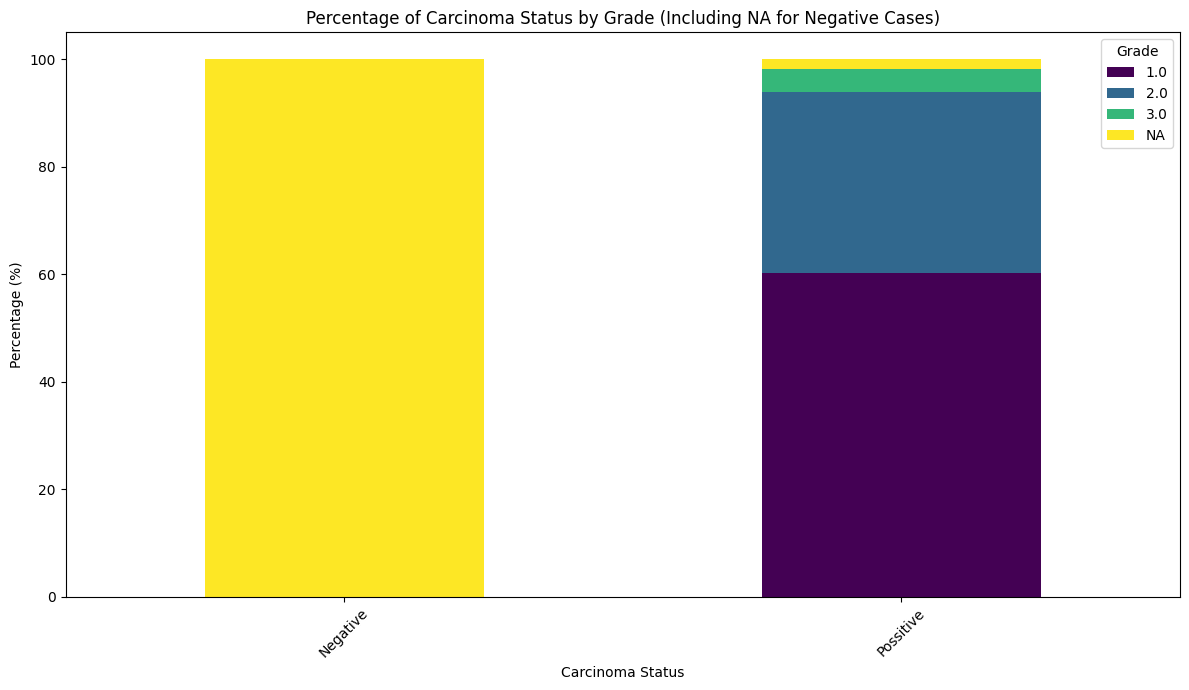

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame
# Replace NA values in 'Grade' with 'NA' to make sure it shows up in the plot
df['Grade'].fillna('NA', inplace=True)

# Group by 'Carcinoma Status' and 'Grade', then count occurrences
grouped = df.groupby(['Carcinoma Status', 'Grade']).size().unstack().fillna(0)

# Calculate the total number of samples for each carcinoma status
total_samples = grouped.sum(axis=1)

# Calculate the percentage for each grade within each carcinoma status
percentage = (grouped.T / total_samples * 100).T

# Plotting
ax = percentage.plot(kind='bar', stacked=True, figsize=(12, 7), cmap='viridis')

# Customizing the plot
plt.title('Percentage of Carcinoma Status by Grade (Including NA for Negative Cases)')
plt.xlabel('Carcinoma Status')
plt.ylabel('Percentage (%)')
plt.legend(title='Grade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


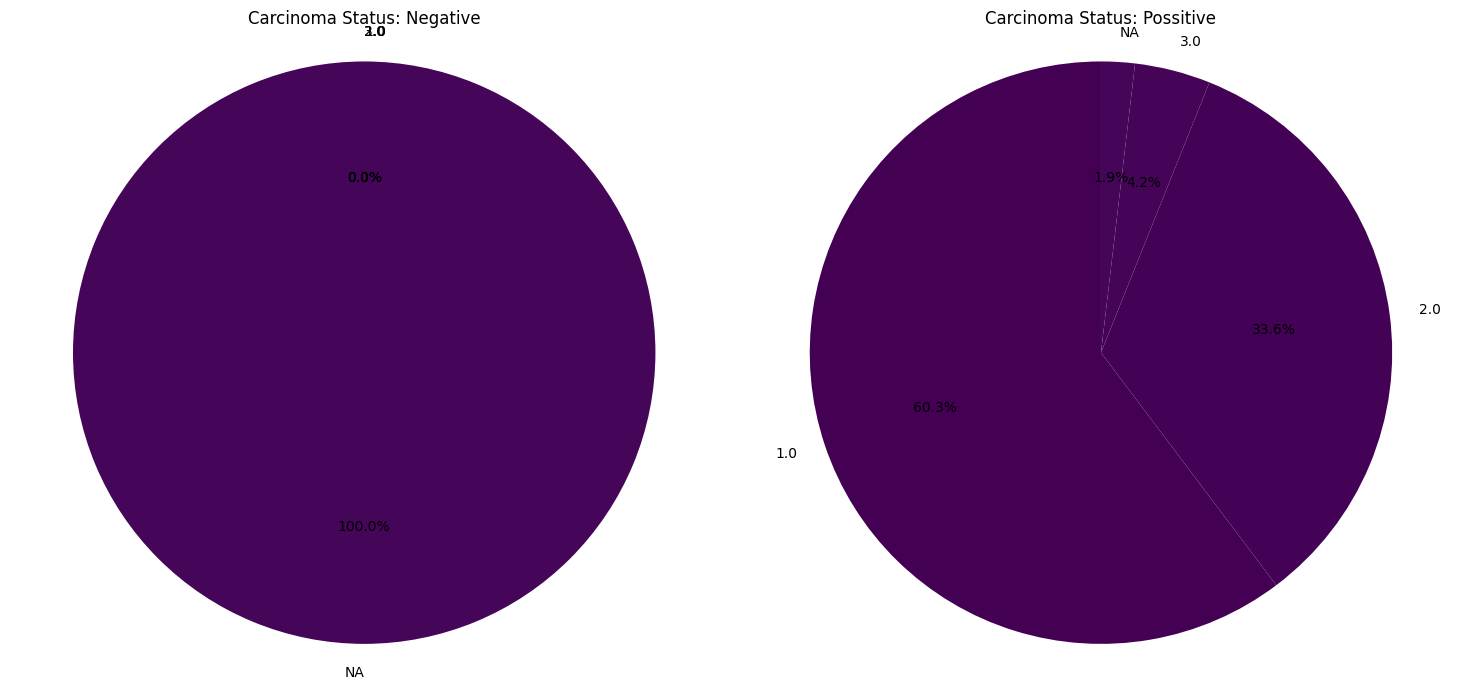

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame
# Replace NA values in 'Grade' with 'NA' to make sure it shows up in the plot
df['Grade'].fillna('NA', inplace=True)

# Group by 'Carcinoma Status' and 'Grade', then count occurrences
grouped = df.groupby(['Carcinoma Status', 'Grade']).size().unstack().fillna(0)

# Plotting pie charts for each carcinoma status
fig, axes = plt.subplots(1, len(grouped), figsize=(15, 7))

# Ensure axes is iterable even if there's only one subplot
if len(grouped) == 1:
    axes = [axes]

for ax, (status, data) in zip(axes, grouped.iterrows()):
    # Plot the pie chart for each carcinoma status
    ax.pie(data, labels=data.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.viridis.colors)
    ax.set_title(f'Carcinoma Status: {status}')
    ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle

# Show the figure
plt.tight_layout()
plt.show()


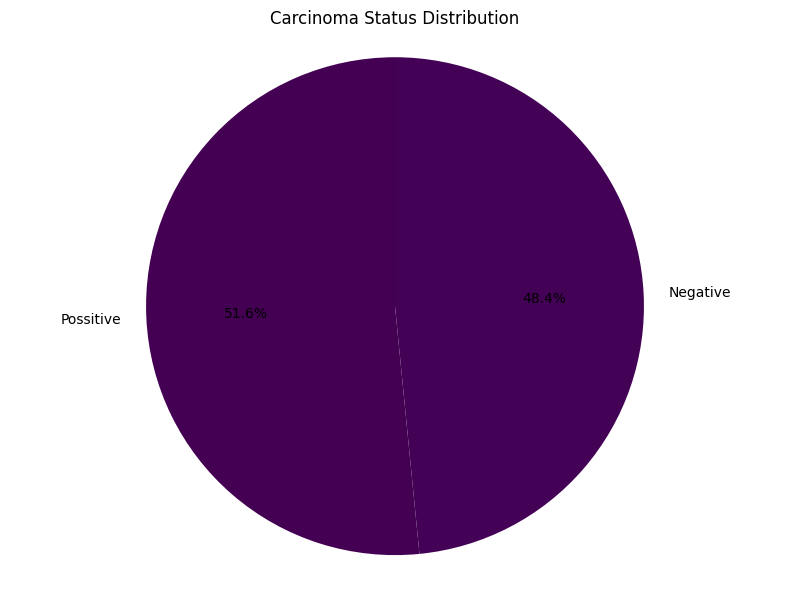

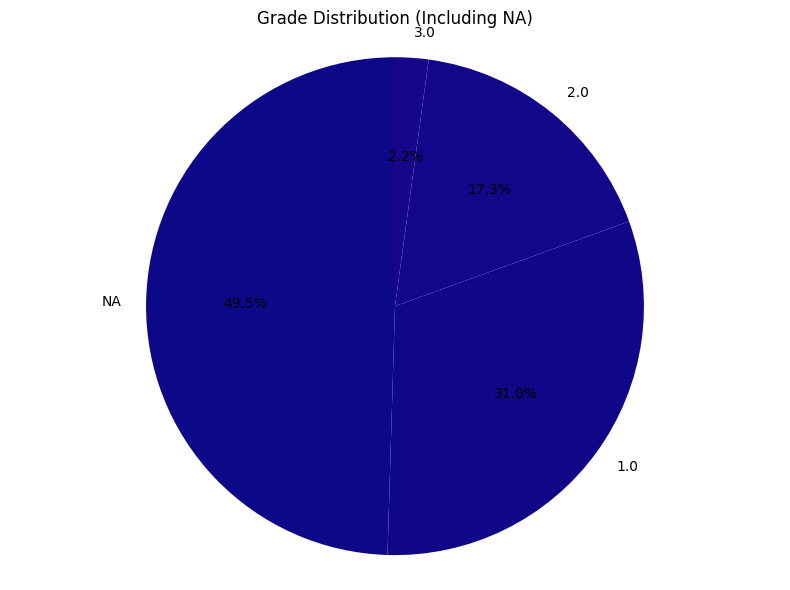

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame
# Replace NA values in 'Grade' with 'NA' to make sure it shows up in the plot
df['Grade'].fillna('NA', inplace=True)

# Plotting the first pie chart for Carcinoma Status
carcinoma_status_count = df['Carcinoma Status'].value_counts()
plt.figure(figsize=(8, 6))
plt.pie(carcinoma_status_count, labels=carcinoma_status_count.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.viridis.colors)
plt.title('Carcinoma Status Distribution')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
plt.tight_layout()
plt.show()

# Plotting the second pie chart for Grade Distribution
grade_count = df['Grade'].value_counts()
plt.figure(figsize=(8, 6))
plt.pie(grade_count, labels=grade_count.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.plasma.colors)
plt.title('Grade Distribution (Including NA)')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
plt.tight_layout()
plt.show()
